# Pneumonia Detection System — corrected notebook

This notebook keeps the original two-stage approach:
1. MobileNetV2 extracts image features.
2. OneClassSVM checks whether an image is similar to the training X-rays.
3. An SVM classifier predicts NORMAL or PNEUMONIA and returns a probability estimate.
4. Gradio provides an upload interface.

**Important:** This is an educational prototype, not a medical diagnostic tool. A displayed probability is not a guarantee of correctness.

**Runtime note:** After a Colab runtime reset, run the cells from top to bottom. Variables in RAM are not preserved by a reset. The training models are saved to Google Drive near the end so they can be preserved for later use.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.svm import OneClassSVM, SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import joblib

DATA_DIR = Path(
    "/content/drive/MyDrive/AI ML_RESEARCH_PAPER/PNEUMONIA/pneumonia/chest_xray/chest_xray"
)
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}\n"
        "Check that Google Drive is mounted and DATA_DIR is correct."
    )

for split in ["train", "val", "test"]:
    for category in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_DIR / split / category
        if not folder.exists():
            raise FileNotFoundError(f"Required dataset folder not found: {folder}")
        count = sum(
            p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
            for p in folder.iterdir()
        )
        print(f"{split}/{category}: {count} valid images")

train/NORMAL: 1341 valid images
train/PNEUMONIA: 3891 valid images
val/NORMAL: 8 valid images
val/PNEUMONIA: 8 valid images
test/NORMAL: 234 valid images
test/PNEUMONIA: 390 valid images


## 1. Preview a few images
This cell is only for visual inspection. It safely skips the preview if the folder has fewer than five valid images.

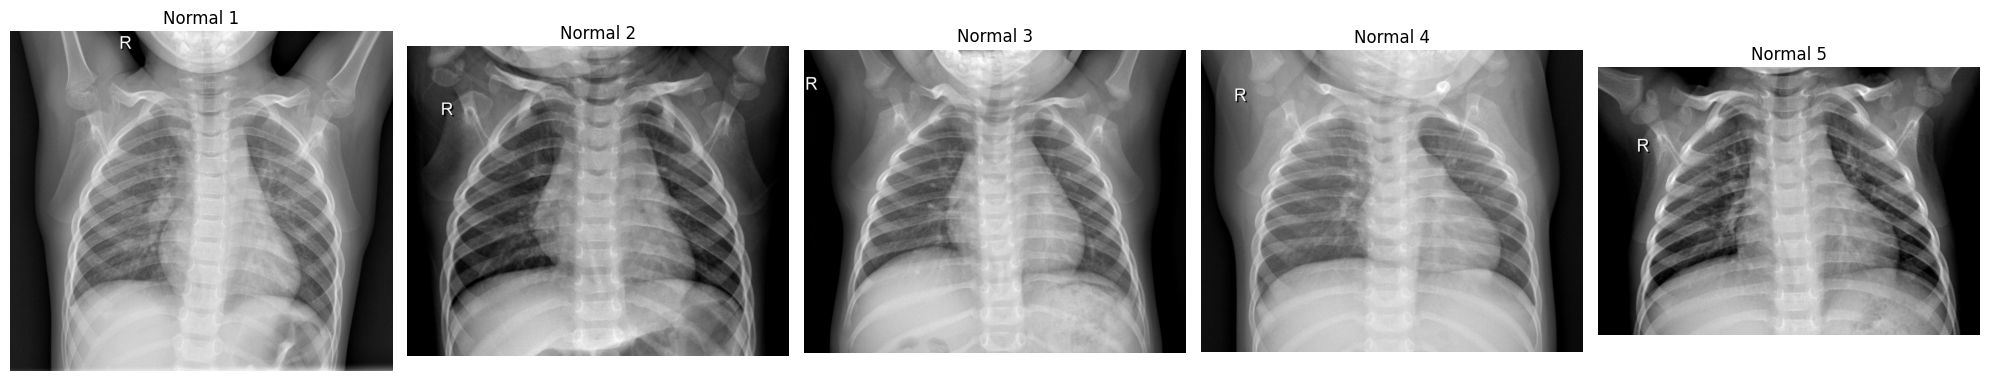

In [3]:
preview_paths = [
    p for p in (DATA_DIR / "train" / "NORMAL").iterdir()
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
]
preview_paths = sorted(preview_paths)[:5]

if preview_paths:
    fig, axes = plt.subplots(1, len(preview_paths), figsize=(4 * len(preview_paths), 4))
    if len(preview_paths) == 1:
        axes = [axes]
    for i, (path, ax) in enumerate(zip(preview_paths, axes)):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"Normal {i + 1}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No valid NORMAL images found to preview.")

## 2. Load the pretrained MobileNetV2 feature extractor

In [4]:
cnn = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)
cnn.trainable = False

print("CNN loaded successfully.")
print("Input shape:", cnn.input_shape)
print("Feature output shape:", cnn.output_shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
CNN loaded successfully.
Input shape: (None, 224, 224, 3)
Feature output shape: (None, 1280)


## 3. Build train/validation image lists
The provided `val` folder in this dataset contains only a small number of images, so this workflow uses an 80/20 split of the `train` folder, as the original notebook did. The `test` folder remains untouched here.

In [5]:
normal_paths = sorted([
    p for p in (DATA_DIR / "train" / "NORMAL").iterdir()
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
])
pneumonia_paths = sorted([
    p for p in (DATA_DIR / "train" / "PNEUMONIA").iterdir()
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
])

all_xray_paths = normal_paths + pneumonia_paths

if not normal_paths or not pneumonia_paths:
    raise ValueError("No valid images found in one or both training class folders.")

xray_train_paths, xray_val_paths = train_test_split(
    all_xray_paths,
    test_size=0.20,
    random_state=42,
    stratify=[0] * len(normal_paths) + [1] * len(pneumonia_paths)
)

print("NORMAL images in source train folder:", len(normal_paths))
print("PNEUMONIA images in source train folder:", len(pneumonia_paths))
print("Training images:", len(xray_train_paths))
print("Validation images:", len(xray_val_paths))

NORMAL images in source train folder: 1341
PNEUMONIA images in source train folder: 3891
Training images: 4185
Validation images: 1047


## 4. Feature extraction
This cell defines the function only. It does not start extraction until the next cells run.

In [6]:
def extract_features(image_paths, batch_size=32):
    valid_paths = [
        Path(p) for p in image_paths
        if Path(p).is_file() and Path(p).suffix.lower() in VALID_EXTENSIONS
    ]

    if not valid_paths:
        raise ValueError("Feature extraction received no valid image files.")

    print("Valid image files:", len(valid_paths))
    print("Skipped files:", len(image_paths) - len(valid_paths))

    feature_batches = []

    for start in tqdm(range(0, len(valid_paths), batch_size), desc="Extracting features"):
        batch_paths = valid_paths[start:start + batch_size]
        batch_images = []

        for path in batch_paths:
            with Image.open(path) as source_img:
                img = source_img.convert("RGB").resize((224, 224))
                batch_images.append(np.asarray(img, dtype=np.float32))

        batch_images = np.asarray(batch_images, dtype=np.float32)
        batch_images = preprocess_input(batch_images)
        batch_features = cnn.predict(batch_images, verbose=0)
        feature_batches.append(batch_features)

    return np.concatenate(feature_batches, axis=0)

In [7]:
X_train_features = extract_features(xray_train_paths)
print("Training feature matrix shape:", X_train_features.shape)

Valid image files: 4185
Skipped files: 0


Extracting features:   0%|          | 0/131 [00:00<?, ?it/s]

Training feature matrix shape: (4185, 1280)


In [8]:
X_val_features = extract_features(xray_val_paths)
print("Validation feature matrix shape:", X_val_features.shape)

Valid image files: 1047
Skipped files: 0


Extracting features:   0%|          | 0/33 [00:00<?, ?it/s]

Validation feature matrix shape: (1047, 1280)


## 5. Model 1 — X-ray-like image detector
This OneClassSVM learns the feature distribution of training X-rays. It can reject some out-of-distribution images, but it is not a guaranteed detector of every non-X-ray image.

In [9]:
xray_detector = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)
xray_detector.fit(X_train_features)
print("X-ray detector training complete.")

X-ray detector training complete.


In [10]:
val_detector_predictions = xray_detector.predict(X_val_features)
accepted = int(np.sum(val_detector_predictions == 1))
rejected = int(np.sum(val_detector_predictions == -1))

print("Total validation images:", len(X_val_features))
print("Accepted as X-ray-like:", accepted)
print("Rejected as outliers:", rejected)
print("Acceptance rate:", round(accepted / len(X_val_features) * 100, 2), "%")

Total validation images: 1047
Accepted as X-ray-like: 1005
Rejected as outliers: 42
Acceptance rate: 95.99 %


## 6. Model 2 — NORMAL vs PNEUMONIA classifier
`probability=True` is enabled here because the prediction function and UI display a class-probability estimate.

In [11]:
y_train = np.asarray([
    0 if path.parent.name == "NORMAL" else 1
    for path in xray_train_paths
], dtype=np.int64)

y_val = np.asarray([
    0 if path.parent.name == "NORMAL" else 1
    for path in xray_val_paths
], dtype=np.int64)

print("Training features:", X_train_features.shape)
print("Training labels:", y_train.shape)
print("Training NORMAL:", int(np.sum(y_train == 0)))
print("Training PNEUMONIA:", int(np.sum(y_train == 1)))
print("Validation features:", X_val_features.shape)
print("Validation labels:", y_val.shape)

Training features: (4185, 1280)
Training labels: (4185,)
Training NORMAL: 1073
Training PNEUMONIA: 3112
Validation features: (1047, 1280)
Validation labels: (1047,)


In [12]:
pneumonia_classifier = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    )
)

pneumonia_classifier.fit(X_train_features, y_train)
print("Pneumonia classifier training complete.")

Pneumonia classifier training complete.


In [13]:
y_val_pred = pneumonia_classifier.predict(X_val_features)
accuracy = accuracy_score(y_val, y_val_pred)

print(f"Validation accuracy: {accuracy * 100:.2f}%")
print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_val, y_val_pred))

Validation accuracy: 97.42%

Classification report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.96      0.95       268
   PNEUMONIA       0.98      0.98      0.98       779

    accuracy                           0.97      1047
   macro avg       0.96      0.97      0.97      1047
weighted avg       0.97      0.97      0.97      1047

Confusion matrix:
[[256  12]
 [ 15 764]]


## 7. Save the trained scikit-learn models to Google Drive
This creates a folder and saves the two trained models. It does not save or alter the dataset.

In [14]:
MODEL_DIR = Path("/content/drive/MyDrive/AI ML_RESEARCH_PAPER/PNEUMONIA/saved_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(xray_detector, MODEL_DIR / "xray_detector.joblib")
joblib.dump(pneumonia_classifier, MODEL_DIR / "pneumonia_classifier.joblib")

print("Saved model files:")
print(MODEL_DIR / "xray_detector.joblib")
print(MODEL_DIR / "pneumonia_classifier.joblib")

Saved model files:
/content/drive/MyDrive/AI ML_RESEARCH_PAPER/PNEUMONIA/saved_models/xray_detector.joblib
/content/drive/MyDrive/AI ML_RESEARCH_PAPER/PNEUMONIA/saved_models/pneumonia_classifier.joblib


## 8. Prediction function
The confidence shown is the classifier's probability estimate for its predicted class; it is not a medical certainty.

In [15]:
def predict_chest_xray(image_path):
    if image_path is None:
        return "Please upload an image."

    try:
        with Image.open(image_path) as source_img:
            img = source_img.convert("RGB").resize((224, 224))
            img_array = np.asarray(img, dtype=np.float32)
    except Exception as exc:
        return f"Could not read this image: {exc}"

    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)
    features = cnn.predict(img_array, verbose=0)

    xray_prediction = xray_detector.predict(features)[0]
    if xray_prediction == -1:
        return "REJECTED: This image was not recognized as an X-ray-like image."

    class_prediction = int(pneumonia_classifier.predict(features)[0])
    probabilities = pneumonia_classifier.predict_proba(features)[0]
    classes = pneumonia_classifier.named_steps["svc"].classes_
    class_index = list(classes).index(class_prediction)
    confidence = float(probabilities[class_index]) * 100

    label = "NORMAL" if class_prediction == 0 else "PNEUMONIA"

    return (
        "X-RAY ACCEPTED\n"
        f"Prediction: {label}\n"
        f"Model probability estimate: {confidence:.2f}%\n\n"
        "Educational prototype only — not a medical diagnosis."
    )

## 9. Optional single-image test
This cell only runs if the example image path exists. You can also test using the Gradio interface below.

In [16]:
example_image = Path("/content/x-ray-pneumonia.jpeg")
if example_image.exists():
    print(predict_chest_xray(str(example_image)))
else:
    print("Example image not found; skipped optional single-image test.")

Example image not found; skipped optional single-image test.


## 10. Gradio upload interface

In [17]:
!pip -q install gradio

In [18]:
import gradio as gr

def predict_image(image_path):
    if image_path is None:
        return "Please upload an image first!"
    return predict_chest_xray(image_path)

with gr.Blocks() as demo:
    gr.Markdown("# 🩻 Pneumonia Detection System")
    gr.Markdown(
        "Upload a chest X-ray image for an educational NORMAL/PNEUMONIA prediction. "
        "This is not a medical diagnostic tool."
    )

    with gr.Row():
        image_input = gr.Image(type="filepath", label="Upload image")
        result_output = gr.Textbox(label="Prediction result", interactive=False)

    predict_button = gr.Button("Analyze Image")
    predict_button.click(
        fn=predict_image,
        inputs=image_input,
        outputs=result_output
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://32fc2fc2374449e5ff.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
